In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_PATH = Path("../data/prices.csv")

In [3]:
df  = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Rows: 61,790
Columns: 16


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
1,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (chicken),94,KG,actual,Retail,MMK,3636.36,3.74
2,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,MMK,3636.36,3.74
3,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,miscellaneous food,Salt,185,KG,actual,Retail,MMK,242.42,0.25
4,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,vegetables and fruits,Onions,173,KG,actual,Retail,MMK,969.70,1.00


In [4]:

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

required_columns = {
    "date", "commodity", "market", "unit",
    "pricetype", "currency", "price"
}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Remove leading/trailing whitespace from text fields without changing their labels.
text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

print("Invalid dates:", df["date"].isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())

display(df.head())

Invalid dates: 0
Exact duplicate rows: 0


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
1,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (chicken),94,KG,actual,Retail,MMK,3636.36,3.74
2,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,MMK,3636.36,3.74
3,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,miscellaneous food,Salt,185,KG,actual,Retail,MMK,242.42,0.25
4,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,vegetables and fruits,Onions,173,KG,actual,Retail,MMK,969.70,1.00


In [5]:
rice = df[
    (df["commodity"] == "Rice (low quality)") &
    (df["unit"] == "KG") &
    (df["pricetype"] == "Retail") &
    (df["currency"] == "MMK")
].copy()

rice["month"] = rice["date"].dt.to_period("M")

rice_monthly = (
    rice.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        observations=("price", "size")
    )
    .reset_index()
)

display(rice_monthly.head())

,market_id,market,month,monthly_price,observations
0,977,Alel Than Kyaw,2008-01,460.0,1
1,977,Alel Than Kyaw,2008-02,450.0,1
2,977,Alel Than Kyaw,2008-03,440.0,1
3,977,Alel Than Kyaw,2008-04,480.0,1
4,977,Alel Than Kyaw,2008-05,480.0,1


In [6]:
rice_coverage = (
    rice_monthly.groupby(["market_id", "market"])
    .agg(
        first_month=("month", "min"),
        last_month=("month", "max"),
        unique_months=("month", "nunique")
    )
    .reset_index()
)

rice_coverage["span_months"] = (
    (rice_coverage["last_month"].dt.year -
     rice_coverage["first_month"].dt.year) * 12
    + rice_coverage["last_month"].dt.month
    - rice_coverage["first_month"].dt.month
    + 1
)

rice_coverage["coverage_pct"] = (
    rice_coverage["unique_months"] /
    rice_coverage["span_months"] * 100
).round(1)

rice_candidates = (
    rice_coverage[
        (rice_coverage["unique_months"] >= 36) &
        (rice_coverage["last_month"].dt.year == 2026)
    ]
    .sort_values("unique_months", ascending=False)
    .reset_index(drop=True)
)

display(rice_candidates)

,market_id,market,first_month,last_month,unique_months,span_months,coverage_pct
0,1658,Lashio Market,2008-01,2026-09,202,225,89.8
1,978,Buthidaung,2008-01,2026-08,162,224,72.3
2,1664,Pakokku Myo Ma Market,2014-01,2026-09,146,153,95.4
3,1661,Kutkai,2014-01,2026-09,130,153,85.0
4,1014,Rathedaung,2008-01,2026-09,123,225,54.7
5,1005,Momauk,2011-02,2026-09,120,188,63.8
6,1019,Taunggyi,2008-01,2026-09,108,225,48.0
7,1656,Mansi,2014-01,2026-08,107,152,70.4
8,1010,Nyaung Chung,2008-01,2026-09,107,225,47.6
9,1655,Bhamo,2014-01,2026-09,98,153,64.1


In [7]:
candidate_ids = rice_candidates["market_id"]

rice_selected = rice_monthly[
    rice_monthly["market_id"].isin(candidate_ids)
]

rice_wide = rice_selected.pivot(
    index="month",
    columns="market_id",
    values="monthly_price"
)

display(rice_wide.head())

market_id,978,986,1005,1010,1014,1019,1024,1653,1655,1656,1658,1661,1664,3276,3280,3281,3285,3286,3289,3292,3293,3297,3302,3304,3307,3308,3311,3315,3321,3332,3333,3341,3345,3346,3352,3353,3354,3626,5225,6084,6085,6086,6087,6088,6089,6090,6091,6376,6377,7443,7928,7930,8027,8028,8470,8551,9094
month,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2008-01,400.0,360.0,NaN,370.0,350.0,320.0,360.0,NaN,NaN,NaN,500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-02,350.0,360.0,NaN,320.0,360.0,300.0,350.0,NaN,NaN,NaN,550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-03,350.0,360.0,NaN,340.0,350.0,NaN,340.0,NaN,NaN,NaN,425.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-04,420.0,380.0,NaN,390.0,420.0,NaN,400.0,NaN,NaN,NaN,450.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-05,500.0,480.0,NaN,500.0,380.0,400.0,400.0,NaN,NaN,NaN,500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
overlap = (
    rice_wide.notna().astype(int).T
    .dot(rice_wide.notna().astype(int))
)

display(overlap)

market_id,978,986,1005,1010,1014,1019,1024,1653,1655,1656,1658,1661,1664,3276,3280,3281,3285,3286,3289,3292,3293,3297,3302,3304,3307,3308,3311,3315,3321,3332,3333,3341,3345,3346,3352,3353,3354,3626,5225,6084,6085,6086,6087,6088,6089,6090,6091,6376,6377,7443,7928,7930,8027,8028,8470,8551,9094
market_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
978,162,69,83,98,103,85,63,32,63,70,149,89,99,55,62,53,51,34,44,38,39,60,62,53,44,62,36,51,51,48,33,29,38,56,47,49,61,49,52,35,46,43,47,46,47,47,46,40,44,28,32,28,28,34,23,25,22
986,69,80,18,57,68,67,57,0,12,12,72,11,13,0,1,1,1,1,0,1,0,1,1,1,0,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1
1005,83,18,120,42,59,34,17,26,94,99,115,109,110,40,42,36,38,26,34,23,27,40,42,41,35,42,26,41,33,31,23,19,27,37,37,37,41,35,35,31,32,30,33,32,33,33,32,30,31,18,24,21,20,23,17,15,12
1010,98,57,42,107,75,66,68,29,22,27,100,47,51,47,51,42,43,33,44,29,33,49,51,49,40,51,28,46,40,41,28,21,32,48,39,43,49,44,41,32,35,32,36,35,36,36,35,31,33,18,24,19,19,23,16,17,12
1014,103,68,59,75,123,58,58,11,51,43,115,56,58,20,20,16,17,13,18,6,16,20,20,19,17,20,8,19,12,17,10,4,12,18,15,19,19,18,15,12,12,11,12,12,12,12,12,10,10,2,3,2,2,3,2,2,2
1019,85,67,34,66,58,108,65,22,19,28,95,36,53,35,42,39,30,16,20,34,18,41,42,29,19,42,29,24,40,23,18,29,24,35,35,33,41,32,42,29,41,36,42,41,42,42,41,35,41,38,39,36,36,42,33,33,33
1024,63,57,17,68,58,65,77,14,4,10,71,16,21,18,20,20,17,8,10,14,11,20,20,17,10,20,17,14,19,11,11,16,10,16,17,19,19,17,20,18,20,18,20,19,20,20,19,17,19,19,20,18,17,20,20,20,18
1653,32,0,26,29,11,22,14,39,19,15,34,38,39,37,39,31,32,18,33,24,28,38,39,38,27,39,17,33,31,30,26,18,24,34,35,34,38,36,37,36,36,33,37,37,37,37,37,32,35,22,25,23,23,24,20,19,16
1655,63,12,94,22,51,19,4,19,98,83,92,96,93,24,24,17,20,14,21,13,17,22,24,24,19,24,8,24,17,19,16,8,18,21,21,21,24,23,22,20,20,18,20,20,20,20,20,19,19,7,11,9,9,10,4,4,4


In [9]:
OUTPUT_DIR = Path("../data/comm")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rice_candidates.to_csv(OUTPUT_DIR / "rice_candidates.csv", index=False)
rice_wide.to_csv(
    OUTPUT_DIR / "rice_wide.csv",
    index=False,
)

print(f"Saved exploration outputs to: {OUTPUT_DIR.resolve()}")


Saved exploration outputs to: D:\machine learning projects\Myanmar-Food-Price-Forecasting\data\comm


<Axes: title={'center': 'Monthly Rice Prices Across Five Myanmar Markets'}, xlabel='Month', ylabel='Price (MMK per KG)'>

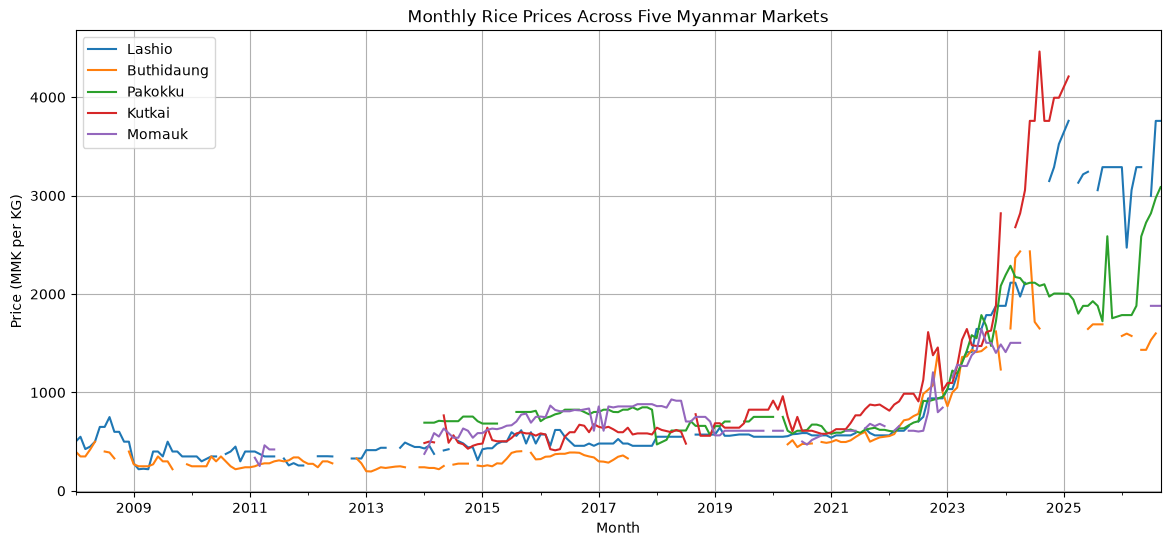

In [10]:
selected_ids = [1658, 978, 1664, 1661, 1005]

selected_markets = rice_wide[selected_ids].copy()

selected_markets.columns = [
    "Lashio",
    "Buthidaung",
    "Pakokku",
    "Kutkai",
    "Momauk"
]

selected_markets.plot(
    figsize=(14, 6),
    title="Monthly Rice Prices Across Five Myanmar Markets",
    xlabel="Month",
    ylabel="Price (MMK per KG)",
    grid=True
)

<Axes: title={'center': 'Relative Rice Price Changes Across Five Markets'}, xlabel='Month', ylabel='Price Index (First Observed = 100)'>

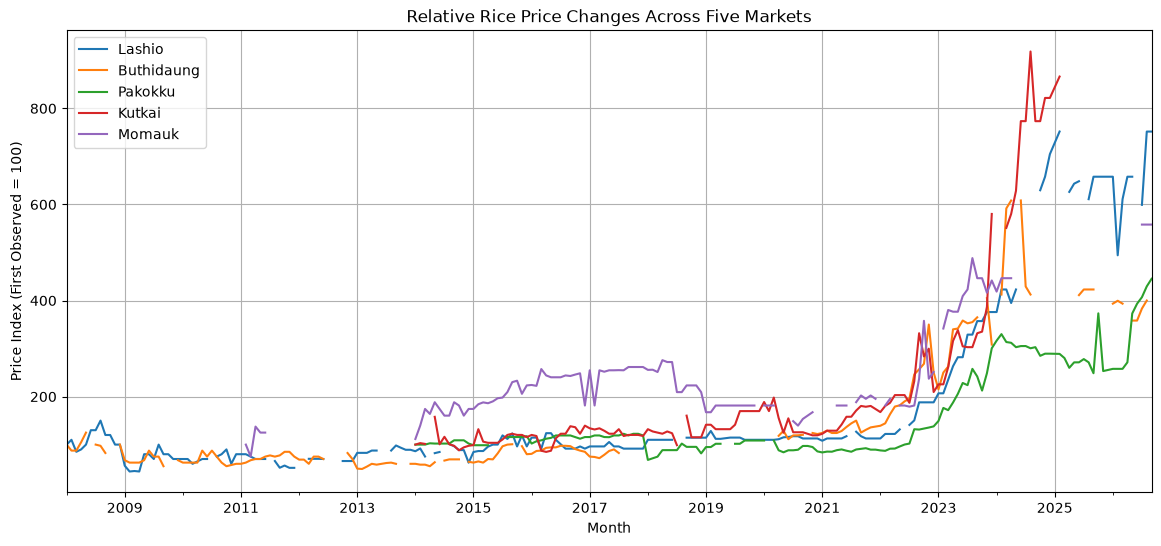

In [11]:
rice_indexed = (
    selected_markets
    .div(selected_markets.bfill().iloc[0])
    * 100
)

rice_indexed.plot(
    figsize=(14, 6),
    title="Relative Rice Price Changes Across Five Markets",
    xlabel="Month",
    ylabel="Price Index (First Observed = 100)",
    grid=True
)

In [21]:
selected_ids =  [1658, 1664, 3280, 3297, 3302, 3308, 3321, 3354, 3626, 5225, 6085, 6086, 6087, 6089, 6090, 6091, 6376, 6377, 7443, 8028, 8470, 8551, 9094, 1019 , 1658, 978, 1664, 1661, 1005]


for market_id in selected_ids:
    market_data = rice_monthly[
        rice_monthly["market_id"] == market_id
    ].copy()

    market_name = market_data["market"].iloc[0]

    observed_months = pd.PeriodIndex(
        market_data["month"],
        freq="M"
    )

    expected_months = pd.period_range(
        start=observed_months.min(),
        end=observed_months.max(),
        freq="M"
    )

    missing_months = expected_months.difference(
        observed_months
    )

    print(f"\n{market_name} (ID: {market_id})")
    print(f"Observed months: {len(observed_months)}")
    print(f"Missing months: {len(missing_months)}")
    print("Missing:", list(missing_months))


Lashio Market (ID: 1658)
Observed months: 202
Missing months: 23
Missing: [Period('2010-07', 'M'), Period('2011-07', 'M'), Period('2012-01', 'M'), Period('2012-02', 'M'), Period('2012-07', 'M'), Period('2012-08', 'M'), Period('2012-09', 'M'), Period('2013-06', 'M'), Period('2013-07', 'M'), Period('2014-04', 'M'), Period('2014-07', 'M'), Period('2018-07', 'M'), Period('2018-08', 'M'), Period('2019-05', 'M'), Period('2021-07', 'M'), Period('2022-06', 'M'), Period('2024-06', 'M'), Period('2024-07', 'M'), Period('2024-09', 'M'), Period('2025-01', 'M'), Period('2025-03', 'M'), Period('2025-07', 'M'), Period('2026-06', 'M')]

Pakokku Myo Ma Market (ID: 1664)
Observed months: 146
Missing months: 7
Missing: [Period('2015-05', 'M'), Period('2015-06', 'M'), Period('2015-07', 'M'), Period('2019-05', 'M'), Period('2019-06', 'M'), Period('2020-02', 'M'), Period('2025-01', 'M')]

Hlaing Bwe Myo Ma market (ID: 3280)
Observed months: 77
Missing months: 1
Missing: [Period('2025-01', 'M')]

Lahe (ID: 3

In [13]:
selected_markets = rice_wide[selected_ids].copy()

missing_summary = pd.DataFrame({
    "observed_months": selected_markets.notna().sum(),
    "missing_months": selected_markets.isna().sum(),
    "missing_pct": (
        selected_markets.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

,observed_months,missing_months,missing_pct
market_id,,,
1658,202,18,8.18
978,162,58,26.36
1664,146,74,33.64
1661,130,90,40.91
1005,120,100,45.45


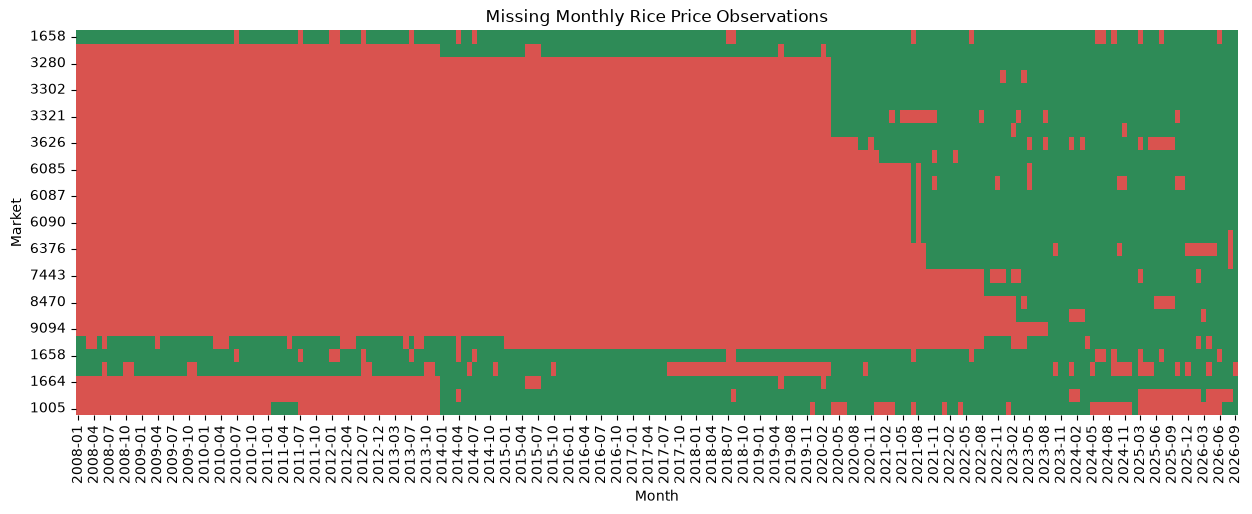

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
selected_markets = [1658, 1664, 3280, 3297, 3302, 3308, 3321, 3354, 3626, 5225, 6085, 6086, 6087, 6089, 6090, 6091, 6376, 6377, 7443, 8028, 8470, 8551, 9094, 1019 , 1658, 978, 1664, 1661, 1005]
plt.figure(figsize=(15, 5))

sns.heatmap(
    rice_wide.loc[:, selected_markets].isna().T,
    cmap=["#2E8B57", "#D9534F"],
    cbar=False
)

plt.title("Missing Monthly Rice Price Observations")
plt.xlabel("Month")
plt.ylabel("Market")
plt.show()

In [15]:
lashio = (
    rice_monthly[
        rice_monthly["market_id"] == 1019
    ]
    .sort_values("month")
    .copy()
)

lashio["interval_months"] = (
    lashio["month"].diff().apply(
        lambda x: x.n if pd.notna(x) else None
    )
)

display(
    lashio[
        ["month", "monthly_price", "interval_months"]
    ].tail(30)
)

,month,monthly_price,interval_months
2564,2023-12,2538.00,1.0
2565,2024-01,2538.00,1.0
2566,2024-02,2350.00,1.0
2567,2024-03,2350.00,1.0
2568,2024-05,2232.00,2.0
2569,2024-06,2185.15,1.0
2570,2024-07,2303.00,1.0
2571,2024-08,2350.00,1.0
2572,2024-09,2585.00,1.0
2573,2024-10,2867.00,1.0


In [25]:
markets = {}

for market_id in [1658, 978, 1664, 983, 997, 1661, 1370, 1657, 1014, 1020, 1005, 1000, 1012, 1002, 1019, 1021, 1656, 1010, 1655, 1023, 988, 1001, 1015, 1382, 986, 3280, 3302, 3308, 1024, 981, 3297, 3354, 1482, 3299, 3281, 3346, 3276, 5225, 3321, 1662, 3353, 6087, 6089, 6090, 3326, 3626, 3304, 6085, 6088, 6091, 3285, 989, 998, 3352, 6377, 3315, 980, 990, 993, 1017, 1018, 3332, 6086, 3320, 1013, 3348, 3312, 1670, 1659, 3288, 6376, 3289, 3307, 5230, 3313, 3347, 8028, 6077, 5231, 3309, 3306, 3334, 5229, 6084, 3292, 3311, 1663, 7928, 3338, 3305, 3294, 995, 3278, 3293, 3323, 3337, 3279, 7443, 5602, 3277, 3327, 3345, 1667, 1668, 8027, 7930, 3317, 1653, 8551, 3286, 3341, 8470, 3310, 3283, 3333, 977, 9094, 3282, 3336, 3331, 7924, 1008, 3290, 5232, 1011, 999, 1669, 7920, 3319, 7925, 6079, 3301, 3287, 982, 3325, 3274, 1022, 985, 6374, 6078, 5244, 984, 7921, 8467, 8401, 1353, 1654, 9717, 1009, 3316, 3328, 1003, 1660, 9028, 7923, 1373, 996, 3330, 991, 7926, 1007, 992, 1665, 7439, 987, 8794, 3295, 979, 7927, 1016, 8552, 3303, 3343, 1399, 6378, 3272, 8469, 3275, 3296, 3344, 5228, 5227, 10792, 10794, 8550, 1004, 9675, 10798, 10803, 10644, 9027, 3335, 9679, 9680, 8466, 5226, 1375, 1666, 10804, 3273, 1006, 3284, 3339, 11183, 11184, 11186, 11190, 11191, 11195, 7437, 7438, 11035, 1371, 1376, 9677, 9676, 10085, 9678, 3350, 5235, 8026, 3314, 7436, 1380, 1381, 10802, 3300, 7442, 1377, 3291, 3318, 3349, 10132, 11187, 11034, 8986, 3351, 8402, 11369, 11371, 11372, 11373, 11375, 10799, 1378, 1379, 10351, 8029, 10793, 11714, 11715, 11716, 11331, 10523, 7434, 11192, 11374, 7435, 11330, 11773, 6375, 11194, 1372, 10800, 1374, 5933, 11771, 11772, 10133, 10801, 11193, 12204, 3342, 9095, 11182, 11189, 11332, 11370, 12205, 9832, 5883, 7922, 6373, 10086, 7929, 3322, 7440, 7441, 8399, 8465, 8468, 8795, 8796, 10255, 10795, 10796, 10797, 11185]:
    market_data = (
        rice_monthly[
            rice_monthly["market_id"] == market_id
        ]
        .sort_values("month")
        .copy()
    )

    markets[market_id] = market_data

    market_data["interval_months"] = (
        market_data["month"]
        .astype("int64")
        .diff()
    )

    interval_summary = (
        market_data["interval_months"]
        .value_counts()
        .sort_index()
    )



In [ ]:
lashio["interval_months"].describe()

count    107.000000
mean       2.093458
std        8.895126
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max       93.000000
Name: interval_months, dtype: float64

In [ ]:
selected_ids = [1658, 1005, 1019]

for market_id in selected_ids:
    market_data = (
        rice_monthly[
            rice_monthly["market_id"] == market_id
        ]
        .sort_values("month")
        .copy()
    )

    market_data["month_num"] = (
        market_data["month"].astype("int64")
    )

    market_data["interval"] = (
        market_data["month_num"].diff()
    )

    print(f"\n{market_data['market'].iloc[0]}")

    display(
        market_data.loc[
            market_data["interval"] > 1,
            ["month", "interval", "monthly_price"]
        ]
    )

    




Lashio Market


,month,interval,monthly_price
3876,2010-08,2.0,375.00
3887,2011-08,2.0,329.00
3892,2012-03,3.0,352.00
3896,2012-10,4.0,328.95
3904,2013-08,3.0,438.00
3912,2014-05,2.0,411.00
3914,2014-08,2.0,506.00
3961,2018-09,3.0,572.00
3969,2019-06,2.0,573.00
3994,2021-08,2.0,634.40



Momauk


,month,interval,monthly_price
1634,2014-01,31.0,376.00
1698,2019-06,2.0,611.00
1704,2020-01,2.0,611.00
1707,2020-07,4.0,501.25
1712,2021-04,5.0,610.90
1715,2021-08,2.0,634.40
1720,2022-02,2.0,611.00
1722,2022-05,2.0,611.00
1730,2023-02,2.0,1151.00
1745,2025-02,10.0,1903.59



Taunggyi


,month,interval,monthly_price
2488,2008-05,3.0,400.00
2489,2008-07,2.0,360.00
2498,2009-05,2.0,375.00
2508,2010-06,4.0,400.00
2519,2011-06,2.0,421.00
2528,2012-06,4.0,545.00
2530,2012-10,3.0,610.00
2537,2013-07,3.0,376.00
2538,2013-10,3.0,446.00
2544,2014-05,2.0,423.00


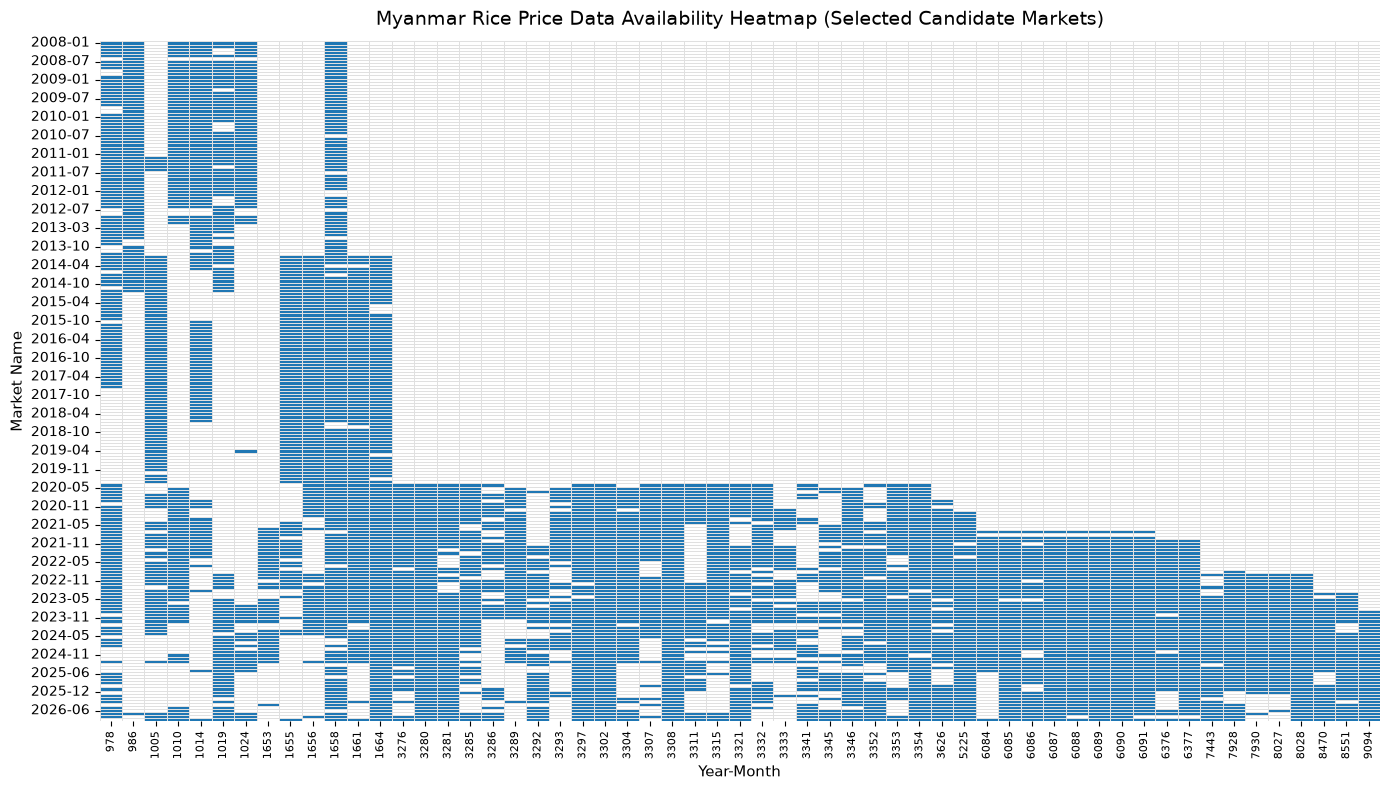

In [28]:
plt.figure(figsize=(14, 8))
# Custom cmap: 0 (white/missing), 1 (blue/present)
sns.heatmap(
    rice_wide.notna().sort_index(), 
    cmap=["#ffffff", "#1f77b4"], 
    cbar=False, 
    linewidths=0.5, 
    linecolor="#e0e0e0"
)

plt.title("Myanmar Rice Price Data Availability Heatmap (Selected Candidate Markets)", fontsize=14, pad=12)
plt.xlabel("Year-Month", fontsize=11)
plt.ylabel("Market Name", fontsize=11)
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()